<a href="https://colab.research.google.com/github/ThomasMZheng/DiscoveryDayGenomics2026/blob/main/Exercises/scripts/QLS_MiCM_DiscoveryDay_Proteomics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Make sure you set the kernel to R!

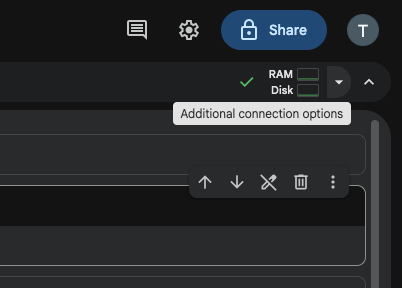

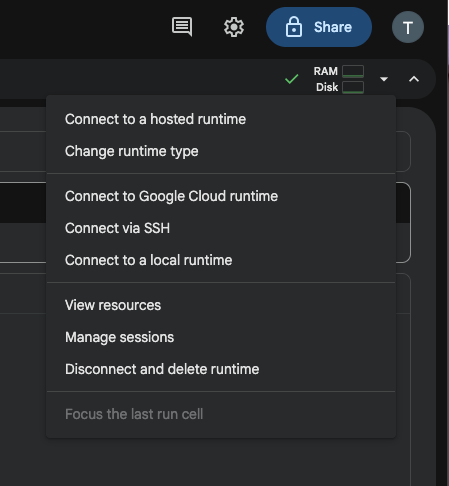

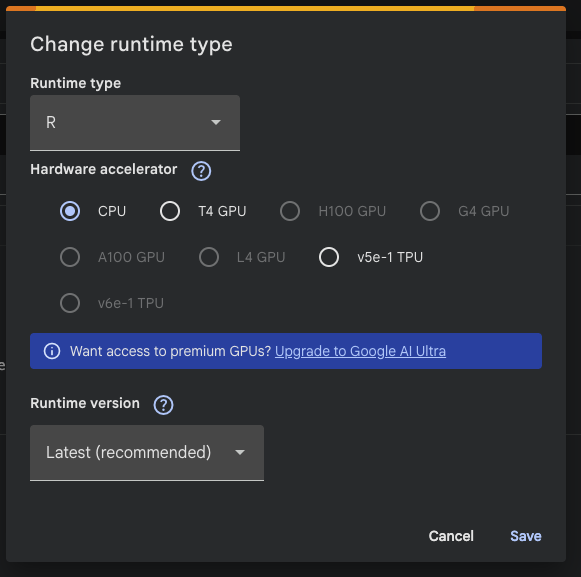

In [ ]:
#library loading
library(tidyverse)
if (!requireNamespace("SomaDataIO")) {
    install.packages("SomaDataIO")
  }
  library(SomaDataIO)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required namespace: SomaDataIO

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

═══════════════════════════════════════════════════════════════════════ Legal ══
   SomaDataIO™
   
   Copyright © 2026 SomaLogic Operating Co., Inc.
   
   The `SomaDataIO` package is licensed under the MIT license
   (`LICENSE.md`) and is intended solely for research use only ("RUO")
   purposes. The code contained herein may *not* be used for
   di

#Welcome to the QLS-MiCM Discovery Day! This rotation is going to be on "Genomics"
Unfortunately, due to time contraints, open-source genetic data is not appropriate (you can find some here: https://www.internationalgenome.org/data-portal/sample)

We will instead be looking at Proteomics! These are protein samples from the blood plasma of human participants

In [ ]:
#Data loading

# 2. Define the RAW URL to the .adat file
raw_url <- "https://raw.githubusercontent.com/QLS-MiCM/Proteogenomics/main/Exercises/data/example_data_v5.0_plasma.adat"

# 3. Download the file into the Colab environment
download.file(url = raw_url, destfile = "example_data_v5.0_plasma.adat")

# 4. Read the local .adat file into a soma_adat object
df <- read_adat("example_data_v5.0_plasma.adat")

In [ ]:
#This is a proprietary adat file from a proteomics company known as SomaLogic

dim(df)
head(df)

[1]   295 11119

,PlateId,PlateRunDate,ScannerID,PlatePosition,SlideId,Subarray,SampleId,SampleType,PercentDilution,SampleMatrix,⋯,seq.9984.12,seq.9986.14,seq.9987.30,seq.9989.12,seq.9991.112,seq.9993.11,seq.9994.217,seq.9995.6,seq.9997.12,seq.9999.1
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<int>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SS-000006_Set001_258495800012_1,SS-000006_Set001,2024-02-12,SG15214400,A10,258495800012,1,17,Sample,20,NA,⋯,454.0,4970.2,444.7,452.5,4366.2,717.3,1144.3,7140.8,43853.3,3434.6
SS-000006_Set001_258495800001_1,SS-000006_Set001,2024-02-12,SG15214400,A11,258495800001,1,230420,Calibrator,20,NA,⋯,532.5,2967.1,348.9,582.4,1630.3,697.4,1630.5,2973.5,8239.7,1077.2
SS-000006_Set001_258495800004_1,SS-000006_Set001,2024-02-12,SG15214400,A2,258495800004,1,230420,Calibrator,20,NA,⋯,493.8,3111.8,354.4,578.3,1596.5,705.9,1601.3,2832.5,8750.8,1069.5
SS-000006_Set001_258495800010_1,SS-000006_Set001,2024-02-12,SG15214400,A8,258495800010,1,22,Sample,20,NA,⋯,520.1,1092.2,281.2,455.4,819.0,700.6,1242.4,2492.6,15717.0,873.1
SS-000006_Set001_258495800007_2,SS-000006_Set001,2024-02-12,SG15214400,B5,258495800007,2,230233,Buffer,20,NA,⋯,147.4,38.5,51.9,251.3,41.5,128.8,286.8,267.3,46.1,71.0
SS-000006_Set001_258495800009_2,SS-000006_Set001,2024-02-12,SG15214400,B7,258495800009,2,74,Sample,20,NA,⋯,470.2,5913.9,307.0,446.9,338.8,673.8,1657.8,3609.7,22682.2,1835.0


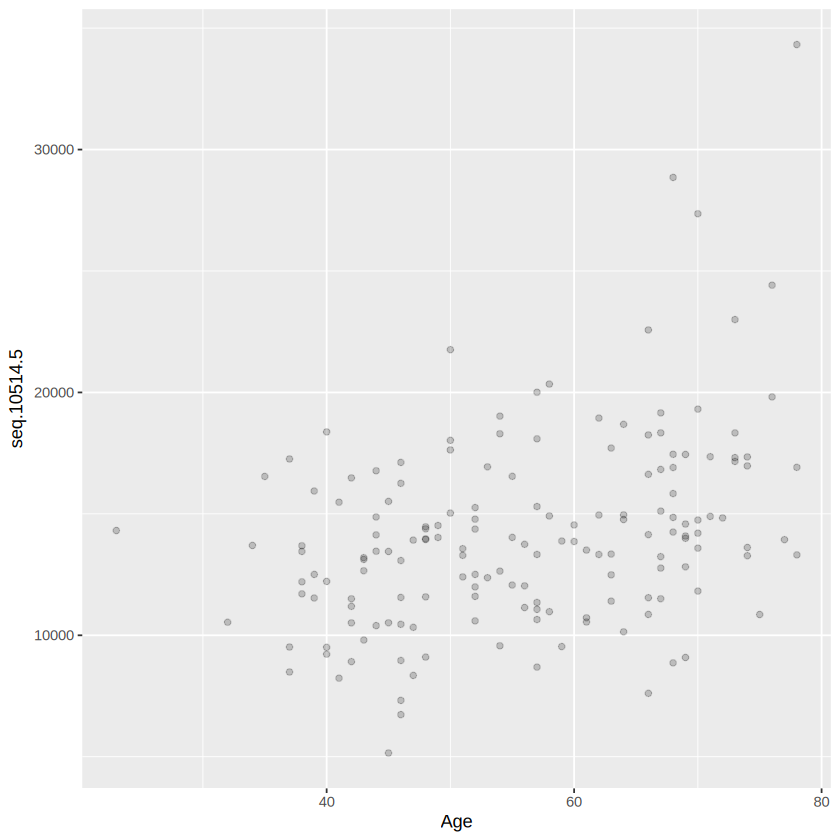

In [ ]:
#Given time, you normally would have QC'd this already - but I'll show you how to actually look at the data for this mini-rotation

dataset <- df %>% filter(!is.na(Age))

ggplot(dataset, aes(x = Age, y = seq.10514.5)) + geom_point(alpha = 0.2)

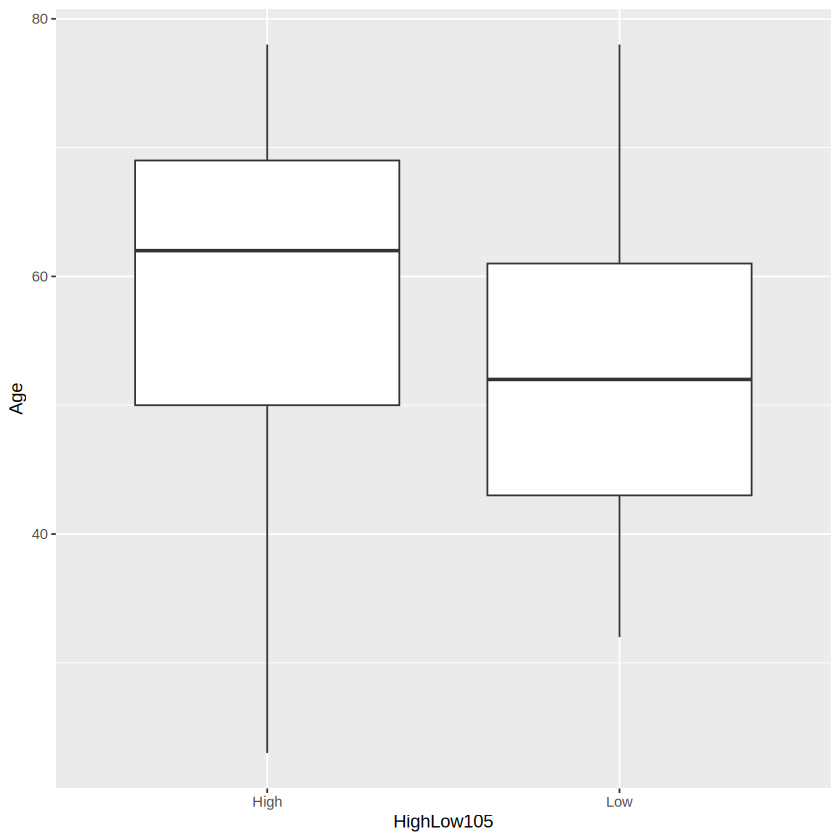

In [ ]:
#Let's just grab the "important" information right now

df <- dataset %>% select(c("SampleId", "Age","Sex","seq.10514.5", "seq.10464.6"))

#Seperates the proteins into High if they are above the median and Low if they are below
df$HighLow105 <- ifelse(df$seq.10514.5 > median(df$seq.10514.5),"High","Low")

#This allows us to run stats on strings
df$HighLow105 <- as.factor(df$HighLow105)


ggplot(df, aes(x = HighLow105, y = Age)) + geom_boxplot()

In [ ]:
t.test(Age ~ HighLow105, df)


	Welch Two Sample t-test

data:  Age by HighLow105
t = 3.731, df = 159.94, p-value = 0.0002645
alternative hypothesis: true difference in means between group High and group Low is not equal to 0
95 percent confidence interval:
  3.205069 10.414021
sample estimates:
mean in group High  mean in group Low 
          59.38272           52.57317 


What does this mean? What could we say about this protein? In fact, what is this protein?



In [ ]:
getAnalyteInfo(df)

AptName,SeqId,SeqIdVersion,SomaId,TargetFullName,Target,UniProt,EntrezGeneID,EntrezGeneSymbol,Organism,⋯,CalQcRatio_SS.000006_Set008_230421,Cal_SS.000006_Set009,CalQcRatio_SS.000006_Set009_230421,Cal_SS.000006_Set010,CalQcRatio_SS.000006_Set010_230421,Cal_SS.000006_Set011,CalQcRatio_SS.000006_Set011_230421,Cal_SS.000006_Set012,CalQcRatio_SS.000006_Set012_230421,Dilution2
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
seq.10514.5,10514-5,3,SL005360,Prostaglandin-H2 D-isomerase,PGD2 synthase,P41222,5730,PTGDS,Human,⋯,0.990,0.9439366,1.027,1.015710,1.016,1.124391,1.039,1.004691,1.003,0.005
seq.10464.6,10464-6,3,SL008696,Anthrax toxin receptor 1,ANTR1,Q9H6X2,84168,ANTXR1,Human,⋯,0.996,1.1117482,1.000,1.022642,1.019,1.071799,0.948,1.037525,1.045,0.200


You can also use the website https://menu.somalogic.com/ which will tell you the same info.

In [ ]:
#Seperates the proteins into High if they are above the median and Low if they are below
df$HighLow104 <- ifelse(df$seq.10464.6 > median(df$seq.10464.6),"High","Low")

#This allows us to run stats on strings
df$HighLow104 <- as.factor(df$HighLow104)

table(df$HighLow104,df$Sex)

Huh, looks like females are more likely to be associated with high protein levels!

We can test this with a chi-squared test!

In [ ]:
chisq.test(df$HighLow104,df$Sex)

In [ ]:
df$quartile105 <- cut(df$seq.10514.5,
                   breaks = quantile(df$seq.10514.5, probs = c(0, 0.25, 0.5, 0.75, 1), na.rm = TRUE),
                   include.lowest = TRUE,
                   labels = c("Q1", "Q2", "Q3", "Q4"))

table(df$quartile105)

#---Now try and run a t.test on age except compare Q4 and Q1-----


#Note that t-tests don't like it when you have more than 2 groups
  #Error in t.test.formula(Age ~ quartile105, df) :
  #  grouping factor must have exactly 2 levels

#Report the p-value!


#---Using the code above, change it so that you split up seq.10464.6 into quartiles and compare Sex

#Report the p-value!

Try the cell above that's commented out!!!

Okay, but running quartiles leads to us throwing away half of our data! What if we don't discretize our proteins?

### Scaling

There are two types of scaling that we discuss in the full workshop:

Z-score scaling and Inverse Normal Transformations (INT)

There are others that suit different methods or applications but we will just focus on Z-score scaling today!

Z-score scaling transforms a value by subtracting the **mean of the variable** (e.g., that specific protein expression across individuals) and dividing by the **standard deviation**.

A Z-score of 1 means the value is 1 standard deviation above the mean, making it easier to interpret how extreme or typical an observation is relative to the rest.

Luckily, R has a built in function, `scale()`, which does this for us!


In [ ]:
#Let's try scaling our seq.10514.5 instead of chunking it!
df <- dataset %>% select(c("SampleId", "Age","Sex","seq.10514.5", "seq.10464.6", "seq.10527.22", "seq.10438.19", "seq.10440.26"))

df$scaled_105 <- scale(df$seq.10514.5)

#We should make this into a factor so that our regression can deal with it
df$Sex <- as.factor(df$Sex)

#Now let's see the correlation

cor(df$Age, df$scaled_105)

#We can even get the p-value like so:

cor.test(df$Age, df$scaled_105)

#Keep in mind, that the correlation is only 0.37, which means that the R^2 is only

cor(df$Age, df$scaled_105)^2

#So Age only explains 14% of the variance found in the protein

ggplot(df, aes(x = Age, y = scaled_105)) + geom_point(alpha = 0.5) + geom_smooth(method = "lm", formula = y ~ x, se = FALSE, color = "red") #+ stat_cor()

#stat_cor is from the ggpubr package and is really convenient! But it has a lot of dependencies, which make it awkward to use in this mini-rotation

Great! But correlation testing isn't the *best* way of looking at this information.

### Linear Regression

The function for linear regressions is a simple `lm()`. (See the geom_smooth method above)


In [ ]:
lm(Age ~ scaled_105, df)

#We can get more information out of the model if we do the following

linear_105 <- lm(scaled_105 ~ Age, df)
summary(linear_105)


What does this mean?

Residuals are the difference between the observed value and the line of best fit. We want to make sure they are normally distributed (Median around 0, 1Q and 3Q are close in magnitude to one another)

Coefficents are the actual "meat" of the regression. This tells us that at the y-intercept, the estimated value of our protein is -1.73 SD from the mean AND that for every year older, on average the protein level is 0.03 SD higher.

Most of the time, the intercept isn't meaningful for proteomics since adults and infants have different proteomic profiles and you can't have a 0 year old adult.

The **slope for Age (0.031)** means that for every additional year of age, the protein level (`scaled_105`) increases by **0.031 standard deviations**, on average.

The Std. Error or Standard Error reflects the **uncertainty** or **variability** in the estimated coefficient. A smaller SE means we're more confident in the precision of our estimate.

This is also reflected in our t value (coming from a t-distribution), and the p-value.

Our overall formula would look something like this:

$$
\text{scaled_105} = -1.733 + 0.03097 \times \text{Age}
$$

This also works for Categorical variables such as Sex.

Try running a linear regression on Sex and our other protein in df `seq.10464.6`.


In [ ]:

#First scale seq.10464.6


#Next, run a basic linear regression comparing Sex to seq.10464.6


#What does SexM mean?


In [ ]:
#If we have extra time:

In [ ]:
multi_linear_105 <- lm(scaled_105 ~ Age + Sex, df)
summary(multi_linear_105)

In [ ]:
#Scale seq.10527.22
df$scaled_1052 <- scale(df$seq.10527.22)
#Run a multi-variate linear regression

#Read out the summary

In [ ]:
#qqnorm(residuals(YOUR_MODEL_HERE))
#qqline(residuals(YOUR_MODEL_HERE))

In [ ]:
ggplot(df, aes(x = Age, y = scaled_1052, colour = Sex)) + geom_point(alpha = 0.2)

In [ ]:
df$scaled_1052 <- ifelse(df$scaled_1052 > 4|df$scaled_1052 < -4, NA, df$scaled_1052)
table(is.na(df$scaled_1052))

In [ ]:
# @title Open if you are done the qq steps
multi_linear_1052 <- lm(scaled_1052 ~ Age + Sex, df)
summary(multi_linear_1052)

df$scaled_1044 <- scale(df$seq.10440.26)
df$scaled_1044 <- ifelse(df$scaled_1044 > 4|df$scaled_1044 < -4, NA, df$scaled_1044)
multi_linear_1044 <- lm(scaled_1044 ~ Age + Sex, df)
summary(multi_linear_1044)

qqnorm(residuals(multi_linear_1044))
qqline(residuals(multi_linear_1044))

hist(df$scaled_1044)


multi_linear_interaction_1044 <- lm(scaled_1044 ~ Age + Sex + Age*Sex, df)
summary(multi_linear_interaction_1044)

#This is an instance of adding an additional covariate results in the loss of significance for another covariate!


#Now try on your own to make a multivariable regression with an interaction term with seq.10438.19

#Also, try without the interaction term and examine what happens to the significance. Why do you think that occurred?


